In [1]:
import torch

# Each row is the embedding vector. 
inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x1)
   [0.55, 0.87, 0.66], # journey  (x2)
   [0.57, 0.85, 0.64], # starts   (x3)
   [0.22, 0.58, 0.33], # with     (x4)
   [0.77, 0.25, 0.10], # one      (x5)
   [0.05, 0.80, 0.55]] # step     (x6)
)

In [27]:
inputs[1]

tensor([0.5500, 0.8700, 0.6600])

In [42]:
query = inputs[1]
attn_scores_2 = torch.empty(inputs.shape[0])
print(attn_scores_2)
for i, x_i in enumerate(inputs):
    # print(i, attn_scores_2[i])
    attn_scores_2[i] = torch.dot(x_i, query)
    # print(i, attn_scores_2[i])


print("[2]Attention Score: ", attn_scores_2)

# convert the scores into normalized weights

attn_weights_2 = torch.softmax(attn_scores_2, dim=0)
print("[2]Attention Weight: ", attn_weights_2)

context_vec_2 = torch.zeros(query.shape)
for i, x_i in enumerate(inputs):
    context_vec_2 += attn_weights_2[i] * x_i

print("[2]Context Vector: ", context_vec_2)
    

tensor([0., 0., 0., 0., 0., 0.])
[2]Attention Score:  tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])
[2]Attention Weight:  tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
[2]Context Vector:  tensor([0.4419, 0.6515, 0.5683])


In [43]:
import torch

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x1)
   [0.55, 0.87, 0.66], # journey  (x2)
   [0.57, 0.85, 0.64], # starts   (x3)
   [0.22, 0.58, 0.33], # with     (x4)
   [0.77, 0.25, 0.10], # one      (x5)
   [0.05, 0.80, 0.55]] # step     (x6)
)

In [51]:
attn_scores = torch.empty(inputs.shape[0], inputs.shape[0])
print(f"Initialized Attention Scores Matrix: \n{attn_scores} \n")

for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attn_scores[i, j] = torch.dot(x_i, x_j)
print("\n", attn_scores)




Initialized Attention Scores Matrix: 
tensor([[0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.]]) 


 tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [52]:
# another way to do this
attn_scores = inputs @ inputs.T
print("\n", attn_scores)


 tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [53]:
attn_weights = torch.softmax(attn_scores, dim=1)
print("\n", attn_weights)



 tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


In [55]:
context_vec = torch.zeros(inputs.shape)
print(f"\n Initialized Context Vector Matrix: \n{context_vec} \n")

for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        context_vec[i] += attn_weights[i][j] * x_j

    
print("\n", context_vec)
 


 Initialized Context Vector Matrix: 
tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]]) 


 tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


In [57]:
# or use this

context_vec = attn_weights @ inputs
context_vec

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])

# Trainable Weights

In [58]:
import torch

# Each row is the embedding vector. 
inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x1)
   [0.55, 0.87, 0.66], # journey  (x2)
   [0.57, 0.85, 0.64], # starts   (x3)
   [0.22, 0.58, 0.33], # with     (x4)
   [0.77, 0.25, 0.10], # one      (x5)
   [0.05, 0.80, 0.55]] # step     (x6)
)

In [60]:
# 3.4.1 computing the attention weights step by step

x_2 = inputs[1]
d_in = inputs.shape[1]
d_out = 2

In [66]:
torch.manual_seed(123)

W_query = torch.nn.Parameter(torch.rand(d_in, d_out))
print(W_query)
print()


W_key = torch.nn.Parameter(torch.rand(d_in, d_out))
print(W_key)
print()

W_value = torch.nn.Parameter(torch.rand(d_in, d_out))
print(W_value)
print()


Parameter containing:
tensor([[0.2961, 0.5166],
        [0.2517, 0.6886],
        [0.0740, 0.8665]], requires_grad=True)

Parameter containing:
tensor([[0.1366, 0.1025],
        [0.1841, 0.7264],
        [0.3153, 0.6871]], requires_grad=True)

Parameter containing:
tensor([[0.0756, 0.1966],
        [0.3164, 0.4017],
        [0.1186, 0.8274]], requires_grad=True)



In [67]:
query_2 = x_2 @ W_query
query_2

tensor([0.4306, 1.4551], grad_fn=<SqueezeBackward4>)

In [163]:
x_2

tensor([0.5500, 0.8700, 0.6600])

In [82]:
keys = inputs @ W_key
values = inputs @ W_value


values

tensor([[0.1855, 0.8812],
        [0.3951, 1.0037],
        [0.3879, 0.9831],
        [0.2393, 0.5493],
        [0.1492, 0.3346],
        [0.3221, 0.7863]], grad_fn=<MmBackward0>)

In [83]:
keys_2 = keys[1]
attn_score_22 = torch.dot(query_2, keys_2)
attn_score_22

tensor(1.8524, grad_fn=<DotBackward0>)

In [84]:
keys.shape

torch.Size([6, 2])

In [85]:
attn_scores_2 = query_2 @ keys.T
attn_scores_2

tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440],
       grad_fn=<SqueezeBackward4>)

In [86]:
d_k = keys.shape[1]

attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=0)
attn_weights_2

tensor([0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820],
       grad_fn=<SoftmaxBackward0>)

In [89]:
context_vec_2 = attn_weights @ values
context_vec_2

tensor([[0.2897, 0.8043],
        [0.3069, 0.8188],
        [0.3063, 0.8173],
        [0.2972, 0.7936],
        [0.2848, 0.7650],
        [0.3043, 0.8105]], grad_fn=<MmBackward0>)

## 3.4.2

In [93]:
import torch.nn as nn

class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_keys = nn.Parameter(torch.rand(d_in, d_out))
        self.W_values = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        keys = inputs @ self.W_keys
        queries = inputs @ self.W_query
        values = inputs @ self.W_values

        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / d_k**0.5, dim=1)
        
        return attn_weights @ values # context_vec

torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
sa_v1(inputs)

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)

In [104]:
import torch.nn as nn

class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_keys = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_values = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        queries = self.W_query(inputs)
        keys = self.W_keys(inputs)
        values = self.W_values(inputs)

        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / d_k**0.5, dim=1)
        
        return attn_weights @ values # context_vec

torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
sa_v1(inputs)

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)

In [105]:
torch.manual_seed(123)
sa_v2 = SelfAttention_v2(d_in, d_out)
sa_v2(inputs)

tensor([[-0.5337, -0.1051],
        [-0.5323, -0.1080],
        [-0.5323, -0.1079],
        [-0.5297, -0.1076],
        [-0.5311, -0.1066],
        [-0.5299, -0.1081]], grad_fn=<MmBackward0>)

## 3.5.1 Applying a causal attention mask

In [106]:
queries = sa_v2.W_query(inputs)
values = sa_v2.W_values(inputs)
keys = sa_v2.W_keys(inputs)

attn_scores = queries @ keys.T
attn_weights = torch.softmax(attn_scores / d_k**0.5, dim=1)

In [107]:
attn_weights

tensor([[0.1717, 0.1762, 0.1761, 0.1555, 0.1627, 0.1579],
        [0.1636, 0.1749, 0.1746, 0.1612, 0.1605, 0.1652],
        [0.1637, 0.1749, 0.1746, 0.1611, 0.1606, 0.1651],
        [0.1636, 0.1704, 0.1702, 0.1652, 0.1632, 0.1674],
        [0.1667, 0.1722, 0.1721, 0.1618, 0.1633, 0.1639],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<SoftmaxBackward0>)

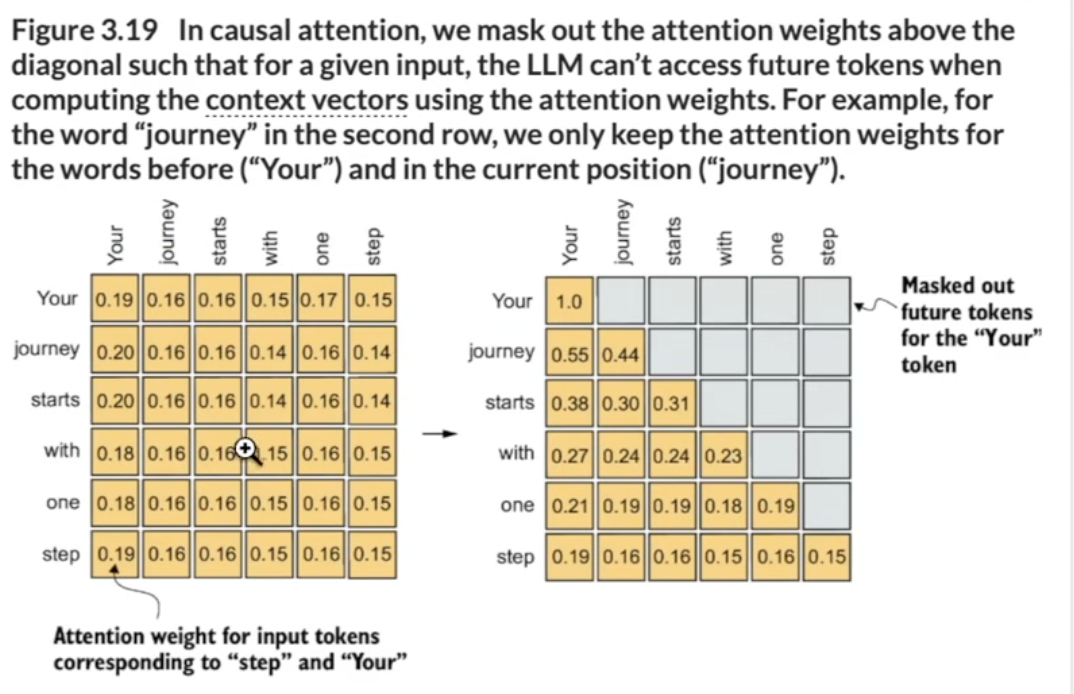

In [109]:
context_length = attn_scores.shape[0]
mask_simple = torch.tril(torch.ones(context_length, context_length))
print(mask_simple)

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])


In [112]:
masked_simple = attn_weights * mask_simple
masked_simple

tensor([[0.1717, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1636, 0.1749, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1637, 0.1749, 0.1746, 0.0000, 0.0000, 0.0000],
        [0.1636, 0.1704, 0.1702, 0.1652, 0.0000, 0.0000],
        [0.1667, 0.1722, 0.1721, 0.1618, 0.1633, 0.0000],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<MulBackward0>)

In [113]:
row_sums = masked_simple.sum(dim=1, keepdim=True)
masked_simple_norm = masked_simple / row_sums
print(masked_simple_norm)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4833, 0.5167, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3190, 0.3408, 0.3402, 0.0000, 0.0000, 0.0000],
        [0.2445, 0.2545, 0.2542, 0.2468, 0.0000, 0.0000],
        [0.1994, 0.2060, 0.2058, 0.1935, 0.1953, 0.0000],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<DivBackward0>)


In [116]:
# making it simpler

mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
print(masked)

tensor([[0.3111,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.1655, 0.2602,   -inf,   -inf,   -inf,   -inf],
        [0.1667, 0.2602, 0.2577,   -inf,   -inf,   -inf],
        [0.0510, 0.1080, 0.1064, 0.0643,   -inf,   -inf],
        [0.1415, 0.1875, 0.1863, 0.0987, 0.1121,   -inf],
        [0.0476, 0.1192, 0.1171, 0.0731, 0.0477, 0.0966]],
       grad_fn=<MaskedFillBackward0>)


In [117]:
attn_weights = torch.softmax(masked / keys.shape[-1]**0.5, dim=1)
attn_weights

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4833, 0.5167, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3190, 0.3408, 0.3402, 0.0000, 0.0000, 0.0000],
        [0.2445, 0.2545, 0.2542, 0.2468, 0.0000, 0.0000],
        [0.1994, 0.2060, 0.2058, 0.1935, 0.1953, 0.0000],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<SoftmaxBackward0>)

## 3.5.2 masking additional attention weights with dropout

In [139]:
torch.manual_seed(123)


layer = nn.Dropout(0.5)

In [140]:
layer(torch.ones(6,6))

tensor([[2., 2., 0., 2., 2., 0.],
        [0., 0., 0., 2., 0., 2.],
        [2., 2., 2., 2., 0., 2.],
        [0., 2., 2., 0., 0., 2.],
        [0., 2., 0., 2., 0., 2.],
        [0., 2., 2., 2., 2., 0.]])

In [141]:
layer(attn_weights)

tensor([[2.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.6816, 0.6804, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.5085, 0.4936, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.3906, 0.0000],
        [0.3249, 0.3418, 0.0000, 0.3308, 0.3249, 0.3363]],
       grad_fn=<MulBackward0>)

In [146]:
batch = torch.stack((inputs,inputs*3), dim = 0)
print(batch.shape)

torch.Size([2, 6, 3])


In [147]:
import torch.nn as nn

class CausalAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_keys = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_values = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))
        
        
    def forward(self, x):
        b, num_tokens, d_in = x.shape # batch = 2,6,3
        queries = self.W_query(x)
        keys = self.W_keys(x)
        values = self.W_values(x)

        attn_scores = queries @ keys.transpose(1, 2)
        attn_scores.masked_fill_(self.mask.bool()[:num_tokens, :num_tokens], -torch.inf)
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=1)
        attn_weights = self.dropout(attn_weights)

        context_vec = attn_weights @ values
        return context_vec

torch.manual_seed(789)
context_length = batch.shape[1]
dropout = 0.0

ca = CausalAttention(d_in, d_out, context_length, dropout)
ca(batch)

tensor([[[-0.0140,  0.0046],
         [-0.0392,  0.0209],
         [-0.0655,  0.0449],
         [-0.0915,  0.0415],
         [-0.0220,  0.2167],
         [-0.2306,  0.0700]],

        [[-0.0265,  0.0087],
         [-0.1672,  0.0846],
         [-0.2655,  0.1762],
         [-0.2348,  0.1019],
         [-0.0414,  0.5426],
         [-0.6534,  0.2821]]], grad_fn=<UnsafeViewBackward0>)

##  Multi Head Attention

In [162]:
class MultiHeadAttentionWrapper(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads=2, qkv_bias=False):
        super().__init__()
        self.heads = nn.ModuleList([
        CausalAttention(d_in, 
                        d_out, 
                        context_length, 
                        dropout, 
                        qkv_bias) for _ in range(num_heads)
        ])

    def forward(self, x):
        return torch.cat([head(x) for head in self.heads], dim=-1)

torch.manual_seed(123)
context_length = batch.shape[1]

d_in, d_out = batch.shape[-1], 2


mha = MultiHeadAttentionWrapper(d_in, d_out, context_length, dropout, num_heads=2)
mha(batch)

tensor([[[-0.0844,  0.0414,  0.0766,  0.0171],
         [-0.2264, -0.0039,  0.2143,  0.1185],
         [-0.4163, -0.0564,  0.3878,  0.2453],
         [-0.5014, -0.1011,  0.4992,  0.3401],
         [-0.7754, -0.1867,  0.7387,  0.4868],
         [-1.1632, -0.3303,  1.1224,  0.8460]],

        [[-0.5395,  0.2646,  0.1511,  0.0337],
         [-0.8407, -0.0674,  0.6240,  0.3848],
         [-1.7239, -0.3104,  1.2548,  0.8427],
         [-1.0239, -0.2493,  1.4237,  0.9469],
         [-2.4448, -0.6371,  2.2963,  1.3848],
         [-2.9287, -0.9113,  3.3670,  2.5684]]], grad_fn=<CatBackward0>)

In [161]:
x = torch.tensor([[1, 2, 3], [4, 5, 6]])
y = torch.tensor([[1, 1, 1], [2, 2, 2]])

torch.cat([x,y], dim=0)

tensor([[1, 2, 3],
        [4, 5, 6],
        [1, 1, 1],
        [2, 2, 2]])

## 3.6.2 Implementing Multi-Head Attention with Weight Splits

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length),
                       diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        # As in `CausalAttention`, for inputs where `num_tokens` exceeds `context_length`, 
        # this will result in errors in the mask creation further below. 
        # In practice, this is not a problem since the LLM (chapters 4-7) ensures that inputs  
        # do not exceed `context_length` before reaching this forward method.

        keys = self.W_key(x) # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim) 
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)
        
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2) 
        
        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec) # optional projection

        return context_vec

torch.manual_seed(123)

batch_size, context_length, d_in = batch.shape
d_out = 2
mha = MultiHeadAttention(d_in, d_out, context_length, 0.0, num_heads=2)

context_vecs = mha(batch)

print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)